## Decision Tree

### 1. Import libraries

In [39]:
import glob

import numpy as np
import pandas as pandas
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV, PredefinedSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.base import clone
from sklearn.feature_selection import VarianceThreshold

#### 2. Data preprocessing

##### 2a. Import CSV files and combine into one dataframe

In [40]:
csv_folder = "../data/raw_data/*.csv"
file_paths = glob.glob(csv_folder)

print(f"Found {len(file_paths)} files")

dataframe_list = [pandas.read_csv(file) for file in file_paths]
dataframe_combined = pandas.concat(dataframe_list, ignore_index=True)
dataframe_combined = dataframe_combined.reset_index(drop=True)

Found 15 files


##### 2b. Overview of data

In [41]:
dataframe_combined.shape

(3385313, 85)

In [42]:
dataframe_combined.head()

,Flow ID,Src IP,Src Port,Dst IP,Dst Port,Protocol,Timestamp,Flow Duration,Total Fwd Packet,Total Bwd packets,...,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Attack Name,Label
0,34.173.20.6-192.168.137.234-443-58644-6,34.173.20.6,443,192.168.137.234,58644,6,14/09/2023 09:24:26 AM,14746364,6,0,...,0.0,0.0,0.0,0.0,14681116.0,0.000000,14681116.0,14681116.0,Benign Traffic,0
1,34.173.20.6-192.168.137.234-443-58646-6,34.173.20.6,443,192.168.137.234,58646,6,14/09/2023 09:24:41 AM,60102110,18,0,...,219123.0,0.0,219123.0,219123.0,14957706.0,190543.248665,15061923.0,14672051.0,Benign Traffic,0
2,52.40.210.103-192.168.137.40-18665-60378-6,52.40.210.103,18665,192.168.137.40,60378,6,14/09/2023 09:24:14 AM,90106769,9,0,...,582529.0,0.0,582529.0,582529.0,29841412.0,319090.538141,30049066.0,29473997.0,Benign Traffic,0
3,10.0.0.3-10.0.0.254-44505-1883-6,10.0.0.3,44505,10.0.0.254,1883,6,14/09/2023 09:24:15 AM,119998980,123,123,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Benign Traffic,0
4,10.0.0.7-10.0.0.254-45727-1883-6,10.0.0.7,45727,10.0.0.254,1883,6,14/09/2023 09:24:15 AM,119998539,123,123,...,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Benign Traffic,0


In [43]:
dataframe_combined.info()

<class 'pandas.DataFrame'>
RangeIndex: 3385313 entries, 0 to 3385312
Data columns (total 85 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   Flow ID                     str    
 1   Src IP                      str    
 2   Src Port                    int64  
 3   Dst IP                      str    
 4   Dst Port                    int64  
 5   Protocol                    int64  
 6   Timestamp                   str    
 7   Flow Duration               int64  
 8   Total Fwd Packet            int64  
 9   Total Bwd packets           int64  
 10  Total Length of Fwd Packet  float64
 11  Total Length of Bwd Packet  float64
 12  Fwd Packet Length Max       float64
 13  Fwd Packet Length Min       float64
 14  Fwd Packet Length Mean      float64
 15  Fwd Packet Length Std       float64
 16  Bwd Packet Length Max       float64
 17  Bwd Packet Length Min       float64
 18  Bwd Packet Length Mean      float64
 19  Bwd Packet Length Std       floa

In [44]:
dataframe_combined["Attack Name"].value_counts()

Attack Name
DoS TCP Flood               2106916
Recon Port Scan              485522
MQTT DDoS Publish Flood      413913
MQTT DoS Connect Flood       238031
Recon OS Scan                 85317
Benign Traffic                32620
Recon Vulnerability Scan       8321
DoS UDP Flood                  3115
DDoS UDP Flood                 2576
DDoS ICMP Flood                2552
MQTT Malformed                 2246
DoS ICMP Flood                 2107
MITM ARP Spoofing              1053
MQTT DoS Publish Flood          953
Recon Ping Sweep                 71
Name: count, dtype: int64

##### 2c. Drop Recon Ping Sweep due to its extremely low sample size

In [45]:
dataframe_combined = dataframe_combined[~dataframe_combined['Attack Name'].isin(['Recon Ping Sweep', 'MITM ARP Spoofing'])].copy()

##### 2c. Replace spaces in columns with "_"

In [46]:
dataframe_combined.columns = dataframe_combined.columns.str.replace(" ", "_")
dataframe_combined.columns.to_list()

['Flow_ID',
 'Src_IP',
 'Src_Port',
 'Dst_IP',
 'Dst_Port',
 'Protocol',
 'Timestamp',
 'Flow_Duration',
 'Total_Fwd_Packet',
 'Total_Bwd_packets',
 'Total_Length_of_Fwd_Packet',
 'Total_Length_of_Bwd_Packet',
 'Fwd_Packet_Length_Max',
 'Fwd_Packet_Length_Min',
 'Fwd_Packet_Length_Mean',
 'Fwd_Packet_Length_Std',
 'Bwd_Packet_Length_Max',
 'Bwd_Packet_Length_Min',
 'Bwd_Packet_Length_Mean',
 'Bwd_Packet_Length_Std',
 'Flow_Bytes/s',
 'Flow_Packets/s',
 'Flow_IAT_Mean',
 'Flow_IAT_Std',
 'Flow_IAT_Max',
 'Flow_IAT_Min',
 'Fwd_IAT_Total',
 'Fwd_IAT_Mean',
 'Fwd_IAT_Std',
 'Fwd_IAT_Max',
 'Fwd_IAT_Min',
 'Bwd_IAT_Total',
 'Bwd_IAT_Mean',
 'Bwd_IAT_Std',
 'Bwd_IAT_Max',
 'Bwd_IAT_Min',
 'Fwd_PSH_Flags',
 'Bwd_PSH_Flags',
 'Fwd_URG_Flags',
 'Bwd_URG_Flags',
 'Fwd_Header_Length',
 'Bwd_Header_Length',
 'Fwd_Packets/s',
 'Bwd_Packets/s',
 'Packet_Length_Min',
 'Packet_Length_Max',
 'Packet_Length_Mean',
 'Packet_Length_Std',
 'Packet_Length_Variance',
 'FIN_Flag_Count',
 'SYN_Flag_Count',
 'R

##### 2d. Drop problematic columns

In [47]:
dataframe_combined = dataframe_combined.drop(columns=["Flow_ID", "Src_IP", "Src_Port", "Dst_IP", "Dst_Port", "Protocol", "Timestamp", "Label"])
dataframe_combined.columns.to_list()

['Flow_Duration',
 'Total_Fwd_Packet',
 'Total_Bwd_packets',
 'Total_Length_of_Fwd_Packet',
 'Total_Length_of_Bwd_Packet',
 'Fwd_Packet_Length_Max',
 'Fwd_Packet_Length_Min',
 'Fwd_Packet_Length_Mean',
 'Fwd_Packet_Length_Std',
 'Bwd_Packet_Length_Max',
 'Bwd_Packet_Length_Min',
 'Bwd_Packet_Length_Mean',
 'Bwd_Packet_Length_Std',
 'Flow_Bytes/s',
 'Flow_Packets/s',
 'Flow_IAT_Mean',
 'Flow_IAT_Std',
 'Flow_IAT_Max',
 'Flow_IAT_Min',
 'Fwd_IAT_Total',
 'Fwd_IAT_Mean',
 'Fwd_IAT_Std',
 'Fwd_IAT_Max',
 'Fwd_IAT_Min',
 'Bwd_IAT_Total',
 'Bwd_IAT_Mean',
 'Bwd_IAT_Std',
 'Bwd_IAT_Max',
 'Bwd_IAT_Min',
 'Fwd_PSH_Flags',
 'Bwd_PSH_Flags',
 'Fwd_URG_Flags',
 'Bwd_URG_Flags',
 'Fwd_Header_Length',
 'Bwd_Header_Length',
 'Fwd_Packets/s',
 'Bwd_Packets/s',
 'Packet_Length_Min',
 'Packet_Length_Max',
 'Packet_Length_Mean',
 'Packet_Length_Std',
 'Packet_Length_Variance',
 'FIN_Flag_Count',
 'SYN_Flag_Count',
 'RST_Flag_Count',
 'PSH_Flag_Count',
 'ACK_Flag_Count',
 'URG_Flag_Count',
 'CWR_Flag_Cou

##### 2f. Drop rows with null values (currently unnecessary as no rows have null values)

In [48]:
dataframe_combined.dropna()

,Flow_Duration,Total_Fwd_Packet,Total_Bwd_packets,Total_Length_of_Fwd_Packet,Total_Length_of_Bwd_Packet,Fwd_Packet_Length_Max,Fwd_Packet_Length_Min,Fwd_Packet_Length_Mean,Fwd_Packet_Length_Std,Bwd_Packet_Length_Max,...,Fwd_Seg_Size_Min,Active_Mean,Active_Std,Active_Max,Active_Min,Idle_Mean,Idle_Std,Idle_Max,Idle_Min,Attack_Name
0,14746364,6,0,63.0,0.0,39.0,0.0,10.500000,16.944025,0.0,...,32,0.0,0.0,0.0,0.0,14681116.0,0.000000,14681116.0,14681116.0,Benign Traffic
1,60102110,18,0,4135.0,0.0,1408.0,0.0,229.722222,490.460505,0.0,...,32,219123.0,0.0,219123.0,219123.0,14957706.0,190543.248665,15061923.0,14672051.0,Benign Traffic
2,90106769,9,0,1164.0,0.0,194.0,0.0,129.333333,97.000000,0.0,...,32,582529.0,0.0,582529.0,582529.0,29841412.0,319090.538141,30049066.0,29473997.0,Benign Traffic
3,119998980,123,123,2157.0,4.0,20.0,0.0,17.536585,2.309257,2.0,...,32,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Benign Traffic
4,119998539,123,123,5411.0,4.0,46.0,0.0,43.991870,5.699433,2.0,...,32,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Benign Traffic
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3385308,210290,1,1,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Recon Vulnerability Scan
3385309,202834,1,1,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Recon Vulnerability Scan
3385310,208211,1,1,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Recon Vulnerability Scan
3385311,132317,1,1,0.0,0.0,0.0,0.0,0.000000,0.000000,0.0,...,20,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,Recon Vulnerability Scan


### 3. Prepare data for model training

##### 3a. Sample smaller subset

In [49]:
def sample_or_take_all(group):
    sample_size = min(len(group), 1000000)
    return group.sample(n=sample_size, random_state=42)

small_df = dataframe_combined.groupby('Attack_Name').apply(sample_or_take_all)
small_df = small_df.reset_index(level=0)

In [50]:
small_df.info()

<class 'pandas.DataFrame'>
Index: 2277273 entries, 6528 to 3384262
Data columns (total 77 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   Attack_Name                 str    
 1   Flow_Duration               int64  
 2   Total_Fwd_Packet            int64  
 3   Total_Bwd_packets           int64  
 4   Total_Length_of_Fwd_Packet  float64
 5   Total_Length_of_Bwd_Packet  float64
 6   Fwd_Packet_Length_Max       float64
 7   Fwd_Packet_Length_Min       float64
 8   Fwd_Packet_Length_Mean      float64
 9   Fwd_Packet_Length_Std       float64
 10  Bwd_Packet_Length_Max       float64
 11  Bwd_Packet_Length_Min       float64
 12  Bwd_Packet_Length_Mean      float64
 13  Bwd_Packet_Length_Std       float64
 14  Flow_Bytes/s                float64
 15  Flow_Packets/s              float64
 16  Flow_IAT_Mean               float64
 17  Flow_IAT_Std                float64
 18  Flow_IAT_Max                float64
 19  Flow_IAT_Min                float6

##### 3b. Shuffle samples

In [51]:
small_df_rnd = small_df.sample(frac=1, random_state=42)
small_df_rnd = small_df_rnd.reset_index(drop=True)

In [52]:
small_df_rnd.info()

<class 'pandas.DataFrame'>
RangeIndex: 2277273 entries, 0 to 2277272
Data columns (total 77 columns):
 #   Column                      Dtype  
---  ------                      -----  
 0   Attack_Name                 str    
 1   Flow_Duration               int64  
 2   Total_Fwd_Packet            int64  
 3   Total_Bwd_packets           int64  
 4   Total_Length_of_Fwd_Packet  float64
 5   Total_Length_of_Bwd_Packet  float64
 6   Fwd_Packet_Length_Max       float64
 7   Fwd_Packet_Length_Min       float64
 8   Fwd_Packet_Length_Mean      float64
 9   Fwd_Packet_Length_Std       float64
 10  Bwd_Packet_Length_Max       float64
 11  Bwd_Packet_Length_Min       float64
 12  Bwd_Packet_Length_Mean      float64
 13  Bwd_Packet_Length_Std       float64
 14  Flow_Bytes/s                float64
 15  Flow_Packets/s              float64
 16  Flow_IAT_Mean               float64
 17  Flow_IAT_Std                float64
 18  Flow_IAT_Max                float64
 19  Flow_IAT_Min                floa

##### 3c. Separate targets and features

In [53]:
features = small_df_rnd.drop(columns=['Attack_Name'])
targets = small_df_rnd['Attack_Name']

In [54]:
targets.head

<bound method NDFrame.head of 0                    DoS TCP Flood
1          MQTT DDoS Publish Flood
2           MQTT DoS Connect Flood
3                    Recon OS Scan
4                    DoS TCP Flood
                    ...           
2277268              DoS TCP Flood
2277269              DoS TCP Flood
2277270     MQTT DoS Connect Flood
2277271            Recon Port Scan
2277272            Recon Port Scan
Name: Attack_Name, Length: 2277273, dtype: str>

##### 3d. Create scaler pipeline

In [55]:
# scaler_pipeline = Pipeline(steps=[
#     ("scaler", StandardScaler())
# ])

### 4. Split data into training and test

In [56]:
features_train, features_test, targets_train, targets_test = train_test_split(features, targets, test_size=0.2, random_state=12, shuffle=True)

### 5. Model Training - Hold-out Validation

##### 5a. Create helper evaluate functions

In [57]:
def evaluate(model, features_data, targets_data):
    prediction = model.predict(features_data)
    return {
        "Accuracy": accuracy_score(targets_data, prediction),
        "Precision": precision_score(targets_data, prediction, average="weighted", zero_division=0),
        "Recall": recall_score(targets_data, prediction, average="weighted", zero_division=0),
        "F1": f1_score(targets_data, prediction, average="weighted", zero_division=0),
        "F1_macro": f1_score(targets_data, prediction, average="macro", zero_division=0),
    }

def evaluate_class_report(model, features_data, targets_data):
    prediction = model.predict(features_data)

    return classification_report(targets_data, prediction, output_dict=True, zero_division=0)



def plot_confusion_matrix(model, features_data, targets_data, title="Confusion Matrix"):
    prediction = model.predict(features_data)
    cm = confusion_matrix(targets_data, prediction)

    fig, ax = plt.subplots(figsize=(10,10))
    display = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=model.classes_)

    display.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation='vertical', values_format="d")
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return cm

def plot_confusion_matrix_norm(model, features_data, targets_data, title="Confusion Matrix"):
    prediction = model.predict(features_data)
    cm_normalized = confusion_matrix(targets_data, prediction, normalize='true')

    fig, ax = plt.subplots(figsize=(10,10))
    display = ConfusionMatrixDisplay(confusion_matrix=cm_normalized, display_labels=model.classes_)

    display.plot(ax=ax, cmap=plt.cm.Blues, xticks_rotation='vertical', values_format=".2f")
    plt.title(title)
    plt.tight_layout()
    plt.show()

    return cm_normalized

##### 5b. Split for validation and gridsearchcv

In [58]:
# split for hold-out validation
X_train, X_val, Y_train, Y_val = train_test_split(features_train, targets_train, test_size=0.2, random_state=7, shuffle=True)

# split for GridSearchCV, stratify=Y_train maintains class proportions
X_train_param, X_val_param, Y_train_param, Y_val_param = train_test_split(X_train, Y_train, test_size=0.2, random_state=7, shuffle=True, stratify=Y_train)

##### 5c. Set parameter grid

In [59]:
# ***** Change Parameters to parameters for decision tree
param_grid = {
    "classifier__criterion": ["gini", "entropy", "log_loss"],
    "classifier__max_depth": [10, 20, 40, None],
    "classifier__min_samples_split": [2, 5, 10],
    "classifier__min_samples_leaf": [1, 2, 5],
    "classifier__max_features": [None, "sqrt", "log2"],
    "classifier__class_weight": ["balanced"]
}

scoring_param = {
    "accuracy": "accuracy",
    "precision_weighted": "precision_weighted",
    "recall_weighted": "recall_weighted",
    "f1_weighted": "f1_weighted",
    "f1_macro": "f1_macro"
}

##### 5d. Combine train and val data for PredefinedSplit

In [60]:
X_combined = pandas.concat([X_train_param, X_val_param])
Y_combined = pandas.concat([Y_train_param, Y_val_param])

XY_fold = np.concatenate([
    np.full(len(X_train_param), -1),
    np.zeros(len(X_val_param))
])

holdout_cv = PredefinedSplit(XY_fold)

##### 5e. Create a raw model

In [61]:
model_holdout = Pipeline(steps=[
    ("classifier", DecisionTreeClassifier(random_state=42))
])

##### 5f. GridSearchCV

In [62]:
import warnings
from sklearn.exceptions import UndefinedMetricWarning

warnings.filterwarnings("ignore", category=UndefinedMetricWarning)


grid_search = GridSearchCV(
    estimator=model_holdout,
    param_grid=param_grid,
    scoring=scoring_param,
    cv=holdout_cv,
    n_jobs=-1,
    verbose=1,
    return_train_score=True,
    refit="f1_macro"
)

##### 5g. Run grid search

In [63]:
grid_search.fit(X_combined, Y_combined)

print("Best Parameters:")
print(grid_search.best_params_)
print("Best Validation Macro F1:")
print(grid_search.best_score_)

Fitting 1 folds for each of 324 candidates, totalling 324 fits


MemoryError: Unable to allocate 125. MiB for an array with shape (14, 1165963) and data type int64

##### 5h. Report all parameter combinations

In [ ]:
# ***** 
grid_results = pandas.DataFrame(grid_search.cv_results_)

grid_results[
    [
        "rank_test_f1_macro",
        "mean_train_f1_macro",
        "mean_test_f1_macro",
        "mean_test_f1_weighted",
        "mean_test_accuracy",
        "mean_test_precision_weighted",
        "mean_test_recall_weighted",
        "params"
    ]
].sort_values("rank_test_f1_macro").head(10)

,rank_test_f1_macro,mean_train_f1_macro,mean_test_f1_macro,mean_test_f1_weighted,mean_test_accuracy,mean_test_precision_weighted,mean_test_recall_weighted,params
54,1,0.976864,0.756267,0.796977,0.796794,0.797383,0.796794,"{'classifier__class_weight': 'balanced', 'clas..."
270,2,0.992102,0.755894,0.796249,0.796372,0.796258,0.796372,"{'classifier__class_weight': 'balanced', 'clas..."
162,2,0.992102,0.755894,0.796249,0.796372,0.796258,0.796372,"{'classifier__class_weight': 'balanced', 'clas..."
81,4,0.996063,0.751884,0.792762,0.792716,0.793063,0.792716,"{'classifier__class_weight': 'balanced', 'clas..."
189,5,0.996063,0.751771,0.792509,0.792575,0.792596,0.792575,"{'classifier__class_weight': 'balanced', 'clas..."
297,5,0.996063,0.751771,0.792509,0.792575,0.792596,0.792575,"{'classifier__class_weight': 'balanced', 'clas..."
271,7,0.959352,0.751020,0.791358,0.790747,0.792358,0.790747,"{'classifier__class_weight': 'balanced', 'clas..."
163,7,0.959352,0.751020,0.791358,0.790747,0.792358,0.790747,"{'classifier__class_weight': 'balanced', 'clas..."
55,9,0.943059,0.748702,0.791134,0.790325,0.792697,0.790325,"{'classifier__class_weight': 'balanced', 'clas..."
243,10,0.907858,0.747504,0.792785,0.790747,0.800186,0.790747,"{'classifier__class_weight': 'balanced', 'clas..."


### 6. Training Model - Hold-out Validation

##### 6a. Train and evaluate model using fit() and predict()

In [ ]:
# After Take the calculated best parameters and run

best_model = clone(model_holdout).set_params(**grid_search.best_params_)

best_model.fit(X_train, Y_train)

holdout_scores = pandas.DataFrame({
    "Train": evaluate(best_model, X_train, Y_train),
    "Validation": evaluate(best_model, X_val, Y_val),
}).T
holdout_scores

# ========================================================================================================================================
# ========================================================================================================================================
# ========================================================================================================================================

# Run using the best calculated parameters

# Optimized Parameters
# best_model = DecisionTreeClassifier(
# 	criterion = "gini",
# 	max_depth = 40,
# 	min_samples_split = 2,
# 	min_samples_leaf = 1,
# 	max_features = None,
# 	class_weight = "balanced"
# )

# # Default Parameters
# # best_model = DecisionTreeClassifier()

# best_model.fit(X_train, Y_train)

# holdout_scores = pandas.DataFrame({
#     "Train": evaluate(best_model, X_train, Y_train),
#     "Validation": evaluate(best_model, X_val, Y_val),
# }).T
# holdout_scores

AttributeError: 'GridSearchCV' object has no attribute 'best_params_'

##### 6b. Classification Reports

In [ ]:
holdout_report_train = pandas.DataFrame(evaluate_class_report(best_model, X_train, Y_train)).T
holdout_report_train

,precision,recall,f1-score,support
Benign Traffic,0.995448,0.987922,0.991671,2.103000e+04
DDoS ICMP Flood,0.929553,0.998155,0.962633,1.626000e+03
DDoS UDP Flood,0.884555,0.998810,0.938216,1.680000e+03
DoS ICMP Flood,0.917456,0.997792,0.955939,1.359000e+03
DoS TCP Flood,1.000000,0.999980,0.999990,6.395070e+05
DoS UDP Flood,0.884749,0.993674,0.936053,2.055000e+03
MQTT DDoS Publish Flood,0.987316,0.992864,0.990082,2.649940e+05
MQTT DoS Connect Flood,0.991205,0.972166,0.981593,1.524390e+05
MQTT DoS Publish Flood,0.975806,1.000000,0.987755,6.050000e+02
MQTT Malformed,0.601592,0.998609,0.750850,1.438000e+03


In [ ]:
holdout_report_val = pandas.DataFrame(evaluate_class_report(best_model, X_val, Y_val)).T
holdout_report_val

,precision,recall,f1-score,support
Benign Traffic,0.880203,0.869330,0.874733,5181.000000
DDoS ICMP Flood,0.405728,0.425000,0.415140,400.000000
DDoS UDP Flood,0.308511,0.345238,0.325843,420.000000
DoS ICMP Flood,0.392405,0.465465,0.425824,333.000000
DoS TCP Flood,0.999451,0.999563,0.999507,160200.000000
DoS UDP Flood,0.379630,0.422680,0.400000,485.000000
MQTT DDoS Publish Flood,0.982613,0.987651,0.985126,66320.000000
MQTT DoS Connect Flood,0.980821,0.964205,0.972442,38134.000000
MQTT DoS Publish Flood,0.851351,0.807692,0.828947,156.000000
MQTT Malformed,0.467290,0.735294,0.571429,340.000000


##### 6c. Confusion Matrices

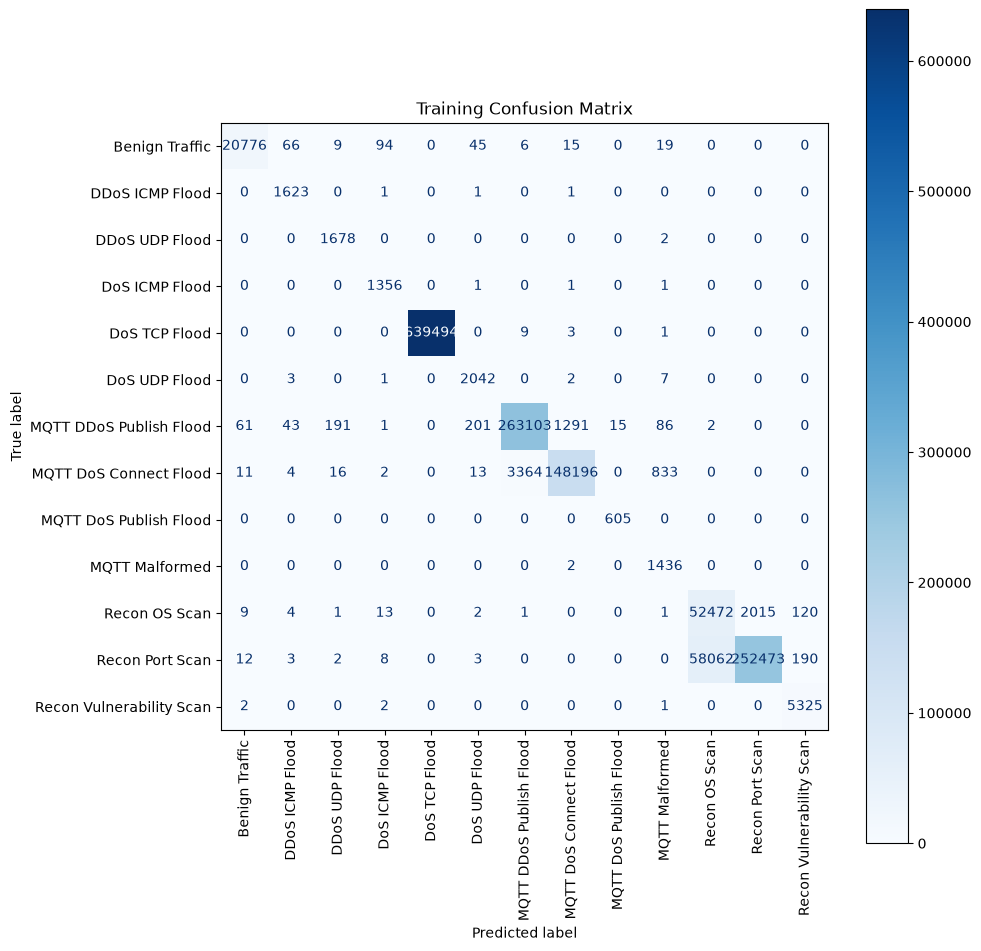

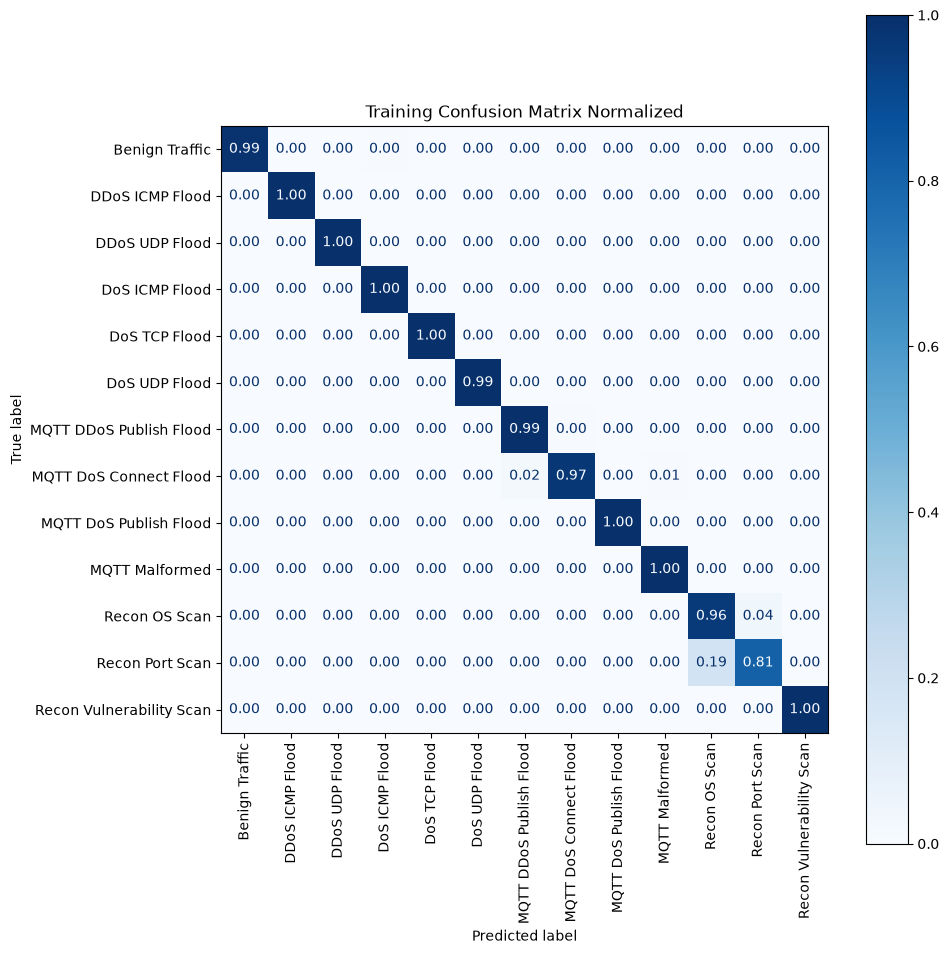

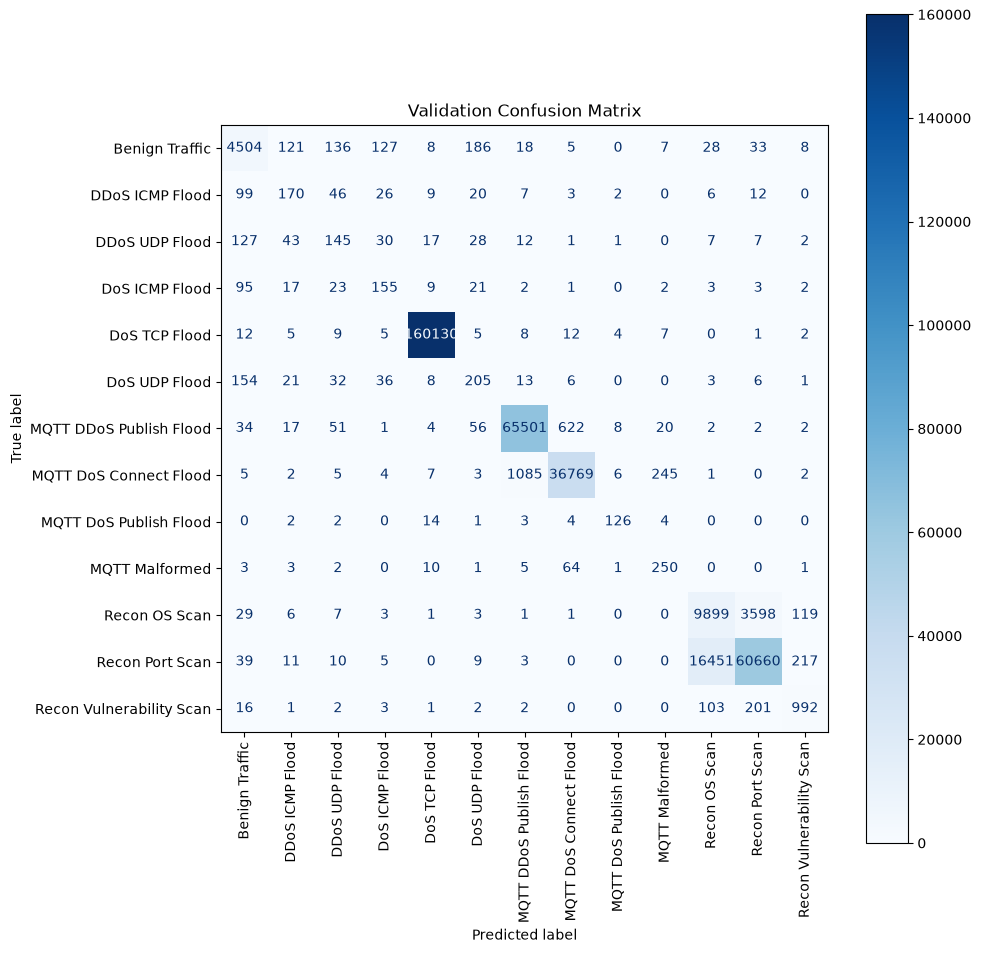

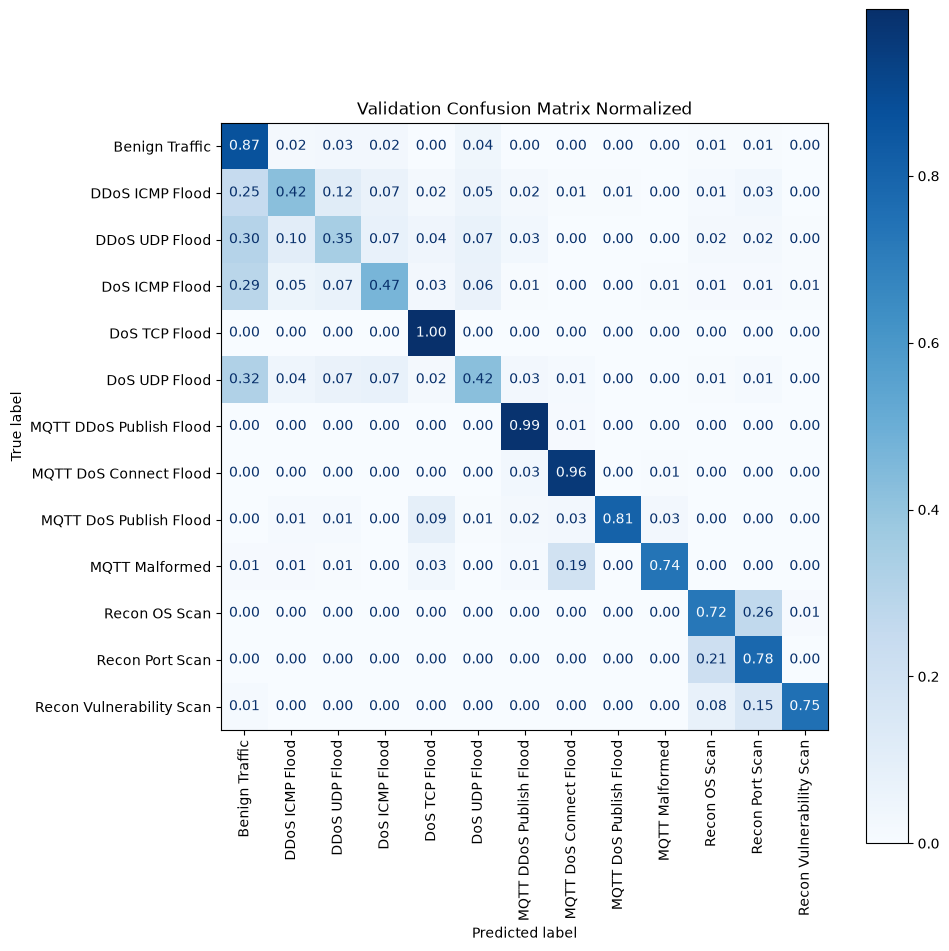

In [ ]:
train_cm = plot_confusion_matrix(
    best_model,
    X_train,
    Y_train,
    title="Training Confusion Matrix"
)

train_cm_norm = plot_confusion_matrix_norm(
    best_model,
    X_train,
    Y_train,
    title="Training Confusion Matrix Normalized"
)

val_cm = plot_confusion_matrix(
    best_model,
    X_val,
    Y_val,
    title="Validation Confusion Matrix"
)

val_cm_norm = plot_confusion_matrix_norm(
    best_model,
    X_val,
    Y_val,
    title="Validation Confusion Matrix Normalized"
)

### 7. Model Training - Stratified K-fold Cross-validation

##### 7a. Set up Stratified K-fold validation

In [ ]:
k = 10
strat_kfold = StratifiedKFold(n_splits=k, shuffle=True, random_state=42)

model_cv = Pipeline(steps=[
    ("classifier", DecisionTreeClassifier(random_state=42))
])

scoring = {
    "accuracy": "accuracy",
    "precision_weighted": "precision_weighted",
    "recall_weighted": "recall_weighted",
    "f1_weighted": "f1_weighted",
    "f1_macro": "f1_macro",
}

best_model_cv = clone(model_cv).set_params(**grid_search.best_params_)

cv_results = cross_validate(
    best_model_cv,
    X_train,
    Y_train,
    cv=strat_kfold,
    scoring=scoring,
    return_train_score=True
)

AttributeError: 'GridSearchCV' object has no attribute 'best_params_'

##### 7b. Dataframe stores fold results

In [ ]:
fold_results = pandas.DataFrame({
    name: cv_results[f"{split}_{metric}"]
    for metric in scoring
    for split, name in [
        ("train", f"Train {metric}"),
        ("test", f"Test {metric}")
    ]
})

fold_results.index = range(1, k + 1)
fold_results.index.name = "Fold"

fold_results.round(4)

,Train accuracy,Test accuracy,Train precision_weighted,Test precision_weighted,Train recall_weighted,Test recall_weighted,Train f1_weighted,Test f1_weighted,Train f1_macro,Test f1_macro
Fold,,,,,,,,,,
1,0.9939,0.7908,0.9940,0.7940,0.9939,0.7908,0.9939,0.7919,0.9946,0.7507
2,0.9928,0.7938,0.9928,0.7947,0.9928,0.7938,0.9928,0.7940,0.9937,0.7527
3,0.9934,0.7966,0.9935,0.7945,0.9934,0.7966,0.9934,0.7953,0.9945,0.7539
4,0.9897,0.7958,0.9898,0.7958,0.9897,0.7958,0.9897,0.7952,0.9889,0.7525
5,0.9898,0.7907,0.9900,0.7903,0.9898,0.7907,0.9898,0.7900,0.9890,0.7486
6,0.9851,0.8042,0.9855,0.8050,0.9851,0.8042,0.9851,0.8045,0.9828,0.7620
7,0.9918,0.8070,0.9919,0.8083,0.9918,0.8070,0.9918,0.8075,0.9920,0.7689
8,0.9907,0.8059,0.9907,0.8068,0.9907,0.8059,0.9907,0.8062,0.9911,0.7671
9,0.9862,0.7921,0.9864,0.7921,0.9862,0.7921,0.9862,0.7918,0.9859,0.7516


##### 7c. Dataframe for summarizing results

In [ ]:
cv_scores = pandas.DataFrame({
    metric: {
        "Mean": cv_results[f"test_{metric}"].mean(),
        "Std": cv_results[f"test_{metric}"].std()
    }
    for metric in scoring
}).T
cv_scores.round(4)

,Mean,Std
accuracy,0.7970,0.0060
precision_weighted,0.7977,0.0061
recall_weighted,0.7970,0.0060
f1_weighted,0.7970,0.0062
f1_macro,0.7561,0.0068


##### 7d. Training and Validation Comparison

In [ ]:
cv_comparison = pandas.DataFrame({
    "Train Mean": [
        cv_results[f"train_{metric}"].mean()
        for metric in scoring
    ],
    "Train Std": [
        cv_results[f"train_{metric}"].std()
        for metric in scoring
    ],
    "Validation Mean": [
        cv_results[f"test_{metric}"].mean()
        for metric in scoring
    ],
    "Validation Std": [
        cv_results[f"test_{metric}"].std()
        for metric in scoring
    ],

}, index=scoring.keys())

cv_comparison["Mean Gap"] = (cv_comparison["Train Mean"] - cv_comparison["Validation Mean"])

cv_comparison.round(4)

,Train Mean,Train Std,Validation Mean,Validation Std,Mean Gap
accuracy,0.9884,0.0065,0.7970,0.0060,0.1915
precision_weighted,0.9888,0.0057,0.7977,0.0061,0.1911
recall_weighted,0.9884,0.0065,0.7970,0.0060,0.1915
f1_weighted,0.9885,0.0063,0.7970,0.0062,0.1915
f1_macro,0.9875,0.0092,0.7561,0.0068,0.2314
